<div align='center'> <h1>WUM 2026, projekt 1</h1> </div>

<div align='center'> <b>Autor</b>: Julia Stasiak</div>
<div align='center'> <b>Data</b>: 08.05.2026</div>


- - -

#### Cel
Ocena jakości działania metody redukcji palety barw przy użyciu algorytmów *k-średnich* oraz *k-median (Kmedoids)*. \
Zbadanie wpływu redukcji palety barw na rozmiar plików oraz skuteczność klasyfikacji binarnej (czy zdjęcie przedstawia kota) przy użyciu algorytmu kNN.

#### Dane
Zbiór 132 zdjęć w formacie .png, o wymiarach 100x100 px, zawierający zdjęcia kotów (kotek-%d.png) oraz kwiatów (kwiatek-%d.png).

- - -

In [230]:
# --- Instalacja ---
%pip install numpy pandas Pillow matplotlib scikit-learn scikit-learn-extra setuptools seaborn

# --- Importy ---
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, f1_score
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn_extra.cluster import KMedoids
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import PolynomialFeatures
import colorsys

warnings.filterwarnings('ignore', category=FutureWarning)

Note: you may need to restart the kernel to use updated packages.


## 1: Przygotowanie zbiorów danych
Wczytujemy 132 obrazy, dokonując dla każdego dekompozycji na pojedyncze piksele, aby uzyskać 2 zbiory danych w postaci data frame:
* (a) **df_pixels**:
    * Nazwa pliku,
    * Kategoria (kot, kwiat),
    * Współrzędna x,
    * Współrzędna y,
    * R, G, B: wartość z zakresu [0,255],
    * H: wartość z zakresu [0,360] - stopnie,
    * S: wartość z zakresu [0,100] - procenty,
    * L: wartość z zakresu [0,100] - procenty,
* (b) **df_colors**:
    * unikatowe kody barw (R, G, B)
    * ilość występowania tych unikalnych barw na zdjęciach kotów oraz kwiatów
    * zmienne binarne:
        * R_dominant/ G_dominant/ B_dominant: czy składowa R/G/B jest tą o największej wartości,
        * is_cool_color (czy zimny): składowa H $\in$[180, 270],
        * is_saturated  (czy nasycony): składowa S > 70,

In [231]:
# 1a

directory = 'kot-kwiat'

def get_pixels():
    imgs_data = []

    for filename in os.listdir(directory):

        category = 'cat' if 'kot' in filename else 'flower'
        file_path = os.path.join(directory, filename)

        with Image.open(file_path) as img:
            img = img.convert('RGB')
            width, height = img.size
            pixels = img.load()

            # Iterujemy po wszystkich pikselach w obrazie.
            for y in range(height):
                for x in range(width):
                    r, g, b = pixels[x, y]

                    # Normalizujemy wartości RGB do zakresu [0,1], aby można było je wykorzystać w funkcji rgb_to_hls.
                    r_norm, g_norm, b_norm = r / 255.0, g / 255.0, b / 255.0

                    # Przekształcamy RGB na HLS.
                    h, l, s = colorsys.rgb_to_hls(r_norm, g_norm, b_norm)

                    imgs_data.append({
                        'img_name': filename,
                        'category': category,
                        'x': x,
                        'y': y,
                        'R': r,
                        'G': g,
                        'B': b,
                        'H': h * 360,           # Skalujemy do wartości w stopniach 0-360.
                        'S': s * 100,           # Skalujemy do wartości w procentach 0-100.
                        'L': l * 100,
                    })

    return pd.DataFrame(imgs_data)

df_pixels = get_pixels()
df_pixels.head()

,img_name,category,x,y,R,G,B,H,S,L
0,kwiatek-76.png,flower,0,0,90,99,30,67.826087,53.488372,25.294118
1,kwiatek-76.png,flower,1,0,97,112,22,70.000000,67.164179,26.274510
2,kwiatek-76.png,flower,2,0,104,122,18,70.384615,74.285714,27.450980
3,kwiatek-76.png,flower,3,0,84,96,11,68.470588,79.439252,20.980392
4,kwiatek-76.png,flower,4,0,70,87,5,72.439024,89.130435,18.039216


In [232]:
# 1b

df_colors = df_pixels.groupby(['R', 'G', 'B', 'H', 'S', 'L', 'category']).size().unstack(fill_value=0).reset_index()
# Usuwamy nazwę 'category' z kolumny
df_colors.columns.name = 'id'
df_colors = df_colors.rename(columns={'cat': 'count_in_cat', 'flower': 'count_in_flower'})

# Obliczenie dominującej składowej RGB w każdym wierszu.
max_rgb_val = df_colors[['R', 'G', 'B']].max(axis=1)

df_colors['R_dominant'] = (df_colors['R'] == max_rgb_val).astype(int)
df_colors['G_dominant'] = (df_colors['G'] == max_rgb_val).astype(int)
df_colors['B_dominant'] = (df_colors['B'] == max_rgb_val).astype(int)

df_colors['is_cool_color'] = (df_colors['H'].between(180, 270)).astype(int)
df_colors['is_saturated'] = (df_colors['S'] > 70).astype(int)

df_colors.head()

id,R,G,B,H,S,L,count_in_cat,count_in_flower,R_dominant,G_dominant,B_dominant,is_cool_color,is_saturated
0,0,0,0,0.0,0.0,0.000000,240,4462,1,1,1,0,0
1,0,0,1,240.0,100.0,0.196078,13,325,0,0,1,1,1
2,0,0,2,240.0,100.0,0.392157,6,62,0,0,1,1,1
3,0,0,3,240.0,100.0,0.588235,2,16,0,0,1,1,1
4,0,0,4,240.0,100.0,0.784314,2,3,0,0,1,1,1


### Weryfikacja poprawności stworzonej bazy
Na podstawie numeru indeksu 4630**84**, wybieramy zdjęcie kota o numerze **42**, a następnie wyświetlamy zdjęcie na podstawie oryginalnego pliku oraz spisanych kodów barw.

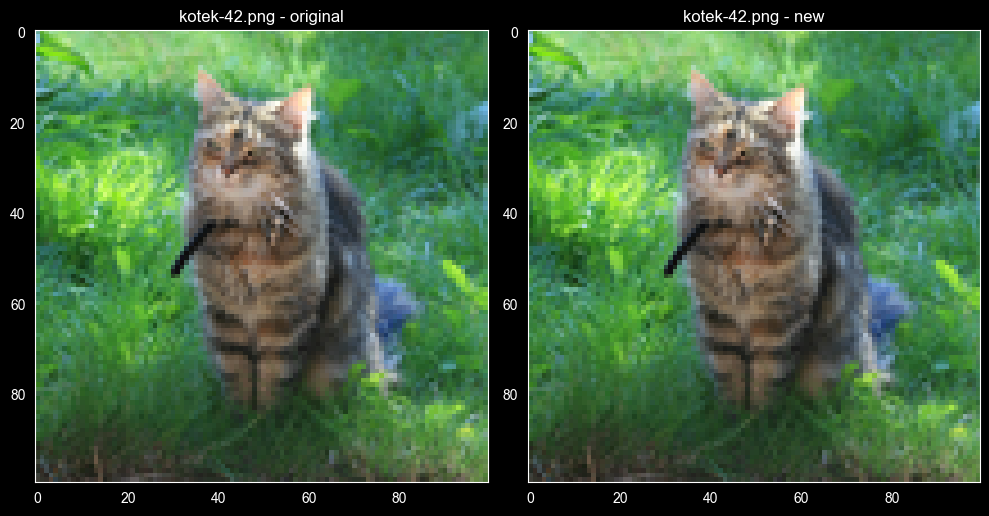

In [234]:
def verify(data_pixels):
    pixels = data_pixels[data_pixels['img_name'] == 'kotek-42.png'].sort_values(['y', 'x'])

    # Tworzymy nowy obrazek na podstawie danych uzyskanych w podpunkcie 1a.
    new_img = pixels[['R', 'G', 'B']].values.reshape((100, 100, 3))

    fig, ax = plt.subplots(1, 2, figsize=(10, 5))

    orig = Image.open('kot-kwiat/kotek-42.png')
    ax[0].imshow(orig)
    ax[0].grid(False)
    ax[0].set_title('kotek-42.png - original')

    ax[1].imshow(new_img)
    ax[1].grid(False)
    ax[1].set_title('kotek-42.png - new')

    plt.tight_layout()
    plt.show()

verify(df_pixels)

Powyższe zestawienie potwierdza poprawność uzyskanych danych w podpunkcie 1a. Obraz kota zrekonstruowany na podstawie uzyskanych wartości RGB zapisanych w *df_pixels* jest taki sam jak obraz oryginalny.

- - -

## 2: Analiza uzyskanych danych

Przygotowane w zadaniu 1 zbiory danych zawierają informacje o 132 obrazach, 55 kotów oraz 77 kwiatów: kolorach ich pikseli, liczbie unikatowych barw, poziomie nasycenia i dominującej barwie RGB. Teraz na ich podstawie możemy przeprowadzić analizę uzyskanych barw.


### 2a: Liczba unikatowych barw - statystyka

In [235]:
# 2a

def print_stats(title, stats):
    print(f'--------------- {title} ---------------')
    print(f'min:{stats['min']:.0f}')
    print(f'max:{stats['max']:.0f}')
    print(f'mean:{stats['mean']:.0f}')
    print(f'median:{stats['50%']:.0f}')
    print(f'standard deviation:{stats['std']:.0f}')
    print('---------------------------------------------------')


unique_colors_per_img = df_pixels.groupby(['img_name', 'category'])[['R', 'G', 'B']].value_counts().groupby(['img_name', 'category']).size().reset_index(name='unique_count')

stats = unique_colors_per_img['unique_count'].describe()
print_stats('UNIQUE COLORS STATS', stats)

stats_c = unique_colors_per_img[unique_colors_per_img['category']=='cat']['unique_count'].describe()
print_stats('UNIQUE COLORS STATS IN CATS IMGS', stats_c)

stats_f = unique_colors_per_img[unique_colors_per_img['category']=='flower']['unique_count'].describe()
print_stats('UNIQUE COLORS STATS IN FLOWERS IMGS', stats_f)

unique_imgs_count = unique_colors_per_img['category'].value_counts()

print('--------------- IMAGES COUNT ---------------')
print(f'Cat images count:{unique_imgs_count['cat']}')
print(f'Flower images count:{unique_imgs_count['flower']}')
print(f'All images count:{unique_imgs_count.sum()}')
print('--------------------------------------------')

--------------- UNIQUE COLORS STATS ---------------
min:4538
max:9911
mean:8649
median:9072
standard deviation:1163
---------------------------------------------------
--------------- UNIQUE COLORS STATS IN CATS IMGS ---------------
min:7339
max:9911
mean:9207
median:9387
standard deviation:575
---------------------------------------------------
--------------- UNIQUE COLORS STATS IN FLOWERS IMGS ---------------
min:4538
max:9881
mean:8251
median:8768
standard deviation:1309
---------------------------------------------------
--------------- IMAGES COUNT ---------------
Cat images count:55
Flower images count:77
All images count:132
--------------------------------------------


### Wnioski:
* Na podstawie powyższych danych można zauważyć, że występuje **duża unikatowość** kolorów: średnia liczba unikalnych kolorów wynosi 8649 (na 10 000 pikseli), co oznacza, że średnio ponad 86% kolorów na zdjęciu ma unikatowy kod koloru.
* Mamy też do czynienia z dysproporcją klas: zdjęć kotów jest mniej niż kwiatów (różnica wynosi 22 zdjęcia). Jednak mimo to, zdjęcia kotów charakteryzują się większa średnią unikalnością kolorów (9207) niż zdjęcia kwiatów (8251), oraz wartością minimalną: koty (7339), kwiaty (4538). Również odchylenie standardowe pokazuje, że zdjęcia kotów (575) mają zbliżone, duże wartości liczby unikalnych barw natomiast kwiaty (1309) są bardziej rozproszone.

### 2b: 5 najczęstszych barw na zdjęciach kotów i kwiatów oraz statystyki dotyczące jasności i nasycenia na zdjęciach.

Top 5 colors in cats images


id,R,G,B,count_in_cat
848247,255,255,255,538
844911,254,254,254,308
0,0,0,0,240
841880,253,253,253,156
826953,246,245,241,78


Top 5 colors in flowers images


id,R,G,B,count_in_flower
0,0,0,0,4462
848247,255,255,255,1331
379,1,1,1,894
948,2,2,2,489
1400,3,3,3,452


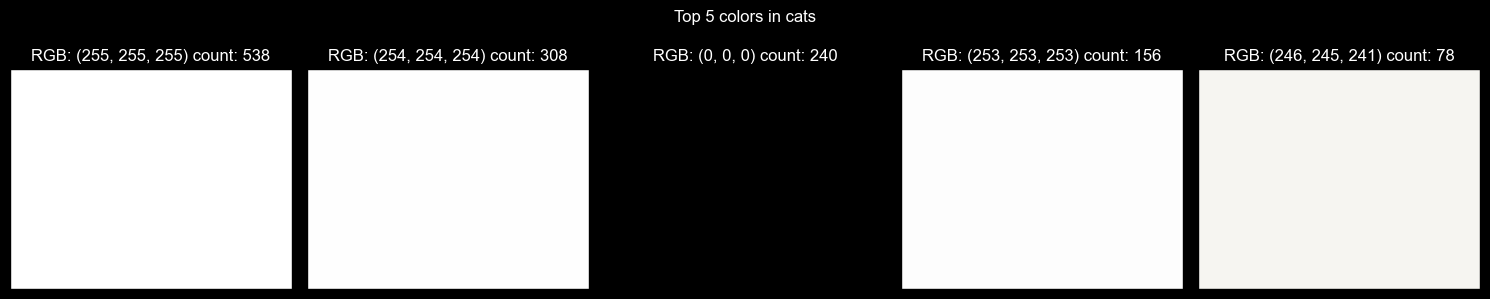

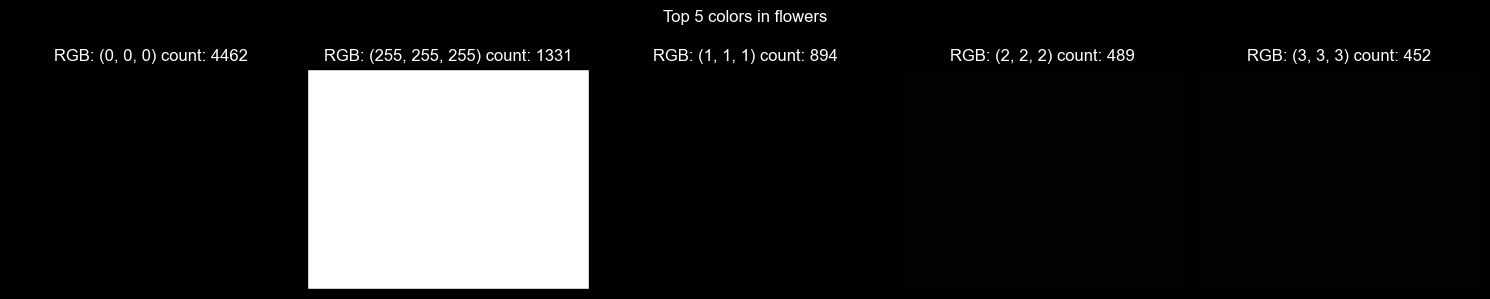

category    L                                            S         \
            min    max       mean     median        std  min    max   
0      cat  0.0  100.0  42.031426  40.392157  20.773922  0.0  100.0   
1   flower  0.0  100.0  36.803196  35.490196  22.538344  0.0  100.0   

                                    
        mean     median        std  
0  31.806681  28.155340  21.697140  
1  46.802753  40.127389  29.610011

In [236]:
def get_5_colors(category):
    if category == 'cat':
        top5 = df_colors.sort_values(by='count_in_cat', ascending=False).head(5)

    else:
        top5 = df_colors.sort_values(by='count_in_flower', ascending=False).head(5)

    return top5

def plot_top_5_colors(top_5_colors, title, count_column):
    fig, axs = plt.subplots(1, 5, figsize=(15, 3))
    fig.suptitle(title)

    for i, (_, row) in enumerate(top_5_colors.iterrows()):
        r, g, b = row['R'] / 255.0 , row['G'] / 255.0, row['B'] / 255.0
        rgb = (int(row['R']), int(row['G']), int(row['B']))
        count = int(row[count_column])
        axs[i].add_patch(plt.Rectangle((0, 0), 1, 1, color=(r, g, b), ec='black'))
        axs[i].axis('off')
        axs[i].set_xlim((0, 1))
        axs[i].set_ylim((0, 1))
        axs[i].set_title(f'RGB: {rgb} count: {count}')

    plt.tight_layout()
    plt.show()


top_5_colors_cat = get_5_colors('cat')
top_5_colors_flower = get_5_colors('flower')

stats = df_pixels.groupby('category')[['L', 'S']].agg(['min', 'max', 'mean', 'median', 'std']).reset_index()
# Usuwamy nazwę 'category' z kolumny
stats.columns.name = 'id'

print("Top 5 colors in cats images")
display(top_5_colors_cat[['R', 'G', 'B', 'count_in_cat']])
print("Top 5 colors in flowers images")
display(top_5_colors_flower[['R', 'G', 'B', 'count_in_flower']])

plot_top_5_colors(top_5_colors_cat, 'Top 5 colors in cats', 'count_in_cat')
plot_top_5_colors(top_5_colors_flower, 'Top 5 colors in flowers', 'count_in_flower')

display(stats)

### Interpretacja i wnioski:
**5 najczęstszych barw**:
* **w zbiorze kotów**: dominacja bieli sugeruje, że wiele zdjęć ma jasne tło bądź zawiera koty o jasnym umaszczeniu. Pojawienie się w zestawieniu również koloru czarnego sugeruje, że oprócz jasnego tła i umaszczenia występuje też czarne futro bądź tylko jego część np. w postaci prążków, jednak rzadziej.
* **w zbiorze kwiatów**: podobnie jak u kotów na podium są kolory bieli i czerni jednak, w przypadku kwiatów to czarnych odcieni jest więcej, jest to efektem ciemniejszego tła podczas robienia zdjęć kwiatów oraz odległości z jakiej się je wykonuje, im bliżej tym ciemniejsze zdjęcie (np. zamiast tła - nieba, jest tło - ziemia).
* **porównanie w obu kategoriach**: W top 5 najczęściej występujących kolorach na zdjęciach kwiatów wartość na pozycji ostatniej i przedostatniej jest zbliżona do wartości w top 5 najczęstszych kolorach na zdjęciach kotów na pozycji 1 (\~500), natomiast pierwsze miejsce (4462) na zdjęciach kwiatów jest \~8 razy większe niż pierwsze miejsce kolorów na zdjęciach kotów (538), co może mieć związek z tym, że baza danych zdjęć kwiatów jest o 22 większa niż kotów, bądź samym faktem, że koty mają większą średnią wartość unikalnych kolorów niż kwiaty.

**Statystyka jasności oraz nasycenia dla zdjęć**
* jasność (L): średnia jasność dla zdjęć kotów (\~42) jest większa niż dla zdjęć kwiatów (\~37). Może to sugerować, że zdjęcia kotów są częściej lepiej doświetlone, bądź bardziej przebija się ten jasny kolor sierści.
* nasycenie (S): średnie nasycenie dla zdjęć kotów (\~28) jest prawie dwukrotnie mniejsze niż to dla zdjęć kwiatów (\~40). Wynika to ze specyfiki zdjęć kwiatów, które składają się często z jasnych, kolorowych płatków, podczas gdy zdjęcia kotów zważając na ich futro są częściej stonowane.


### 2c: Wykresy
Poniżej znajdują się 3 wykresy przedstawiające: \
a) Histogram liczby unikatowych barw na zdjęcie w podziale na zdjęcia kotów oraz kwiatów (dwa histogramy), \
b) Wykres rozrzutu (scatterplot) dla liczby pojawień danej barwy w bazie kotów (współrzędna x) oraz w bazie kwiatów (współrzędna y). Punkty pokolorowane są odpowiadającym kodem RGB, \
c) Osobno dla bazy zdjęć kotów oraz bazy zdjęć kwiatów po wykresie słupkowym skumulowanym (stacked bar chart) dla zmiennej binarnej - czy_zimne (is_cool_color).

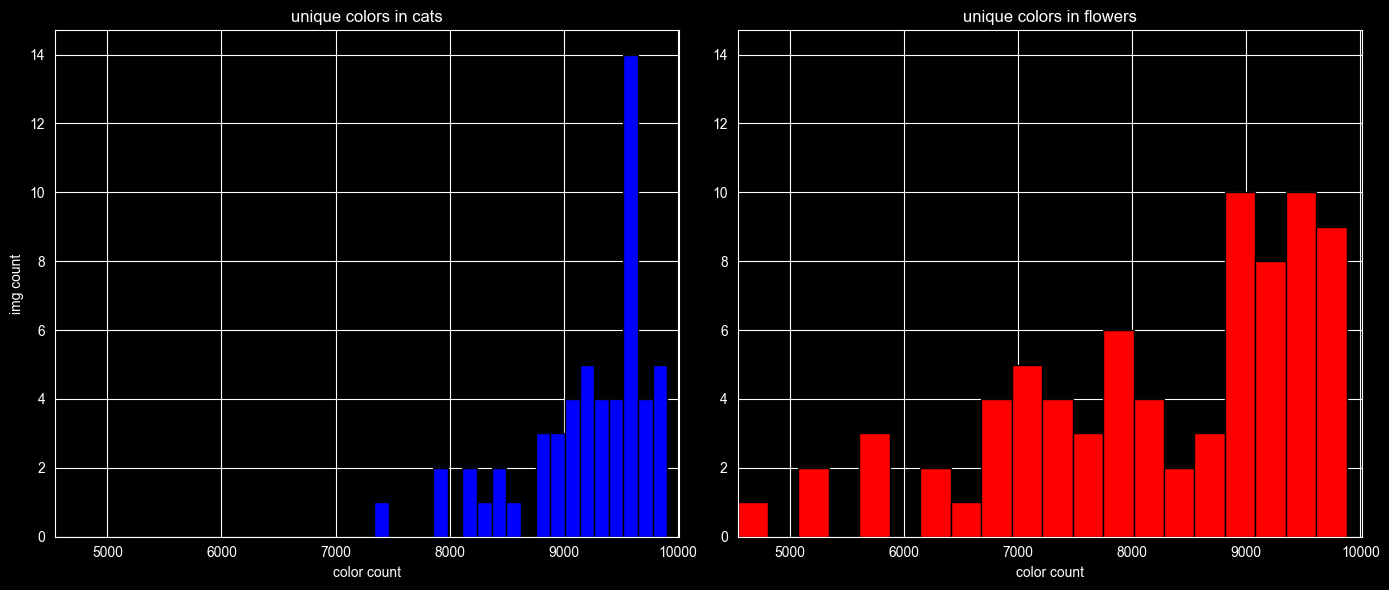

In [237]:
# a
plt.figure(figsize=(14, 6))

cats = unique_colors_per_img[unique_colors_per_img['category'] == 'cat']['unique_count']
flowers = unique_colors_per_img[unique_colors_per_img['category'] == 'flower']['unique_count']

xmin = min(cats.min(), flowers.min())
xmax = max(cats.max(), flowers.max())

ax1 = plt.subplot(1, 2, 1)
plt.hist(cats, color='blue', bins=20, edgecolor='black')
plt.title('unique colors in cats')
plt.xlabel('color count')
plt.ylabel('img count')
plt.xlim(xmin, xmax + 100)

# Używamy sharey=ax1, aby skala Y była taka sama
plt.subplot(1, 2, 2, sharey=ax1)
plt.hist(flowers, color='red', bins=20, edgecolor='black')
plt.title('unique colors in flowers')
plt.xlabel('color count')
plt.xlim(xmin, xmax + 100)

plt.tight_layout()
plt.show()

### Komentarz:
Zarówno zdjęcia kotów, jak i kwiatów charakteryzują się dużą liczbą unikalnych barw. Jednak mają one inny rozkład:
* **Koty**: rozkład liczby unikalnych kolorów jest wyraźnie skoncentrowany po prawej stronie w przedziale [9000, 10000]. Sugeruje to bardzo dużą szczegółowość kolorystyczną dla zdjęć kotów.
* **Kwiaty**: rozkład liczby unikatowych kolorów jest zdecydowanie bardziej rozciągnięty po prawie całej osi. W przeciwieństwie do zdjęć kotów przyjmuje również wartości z przedziału [4000, 7000], co sugeruje, że w porównaniu do kotów, kwiaty nie mają tylko tak szczegółowych kolorystycznie zdjęć, ale też prostsze, zawierające mniejszą ilość unikatowych kolorów.

**Wniosek**:
Bardzo wysoka unikalność barw na zdjęciach potwierdza zgodność postawionej przez analityków tezy: różnica o jedną wartośc na pojedyńczej współrzędnej RGB nie jest aż tak istotna dla przeciętnego odbiorcy.


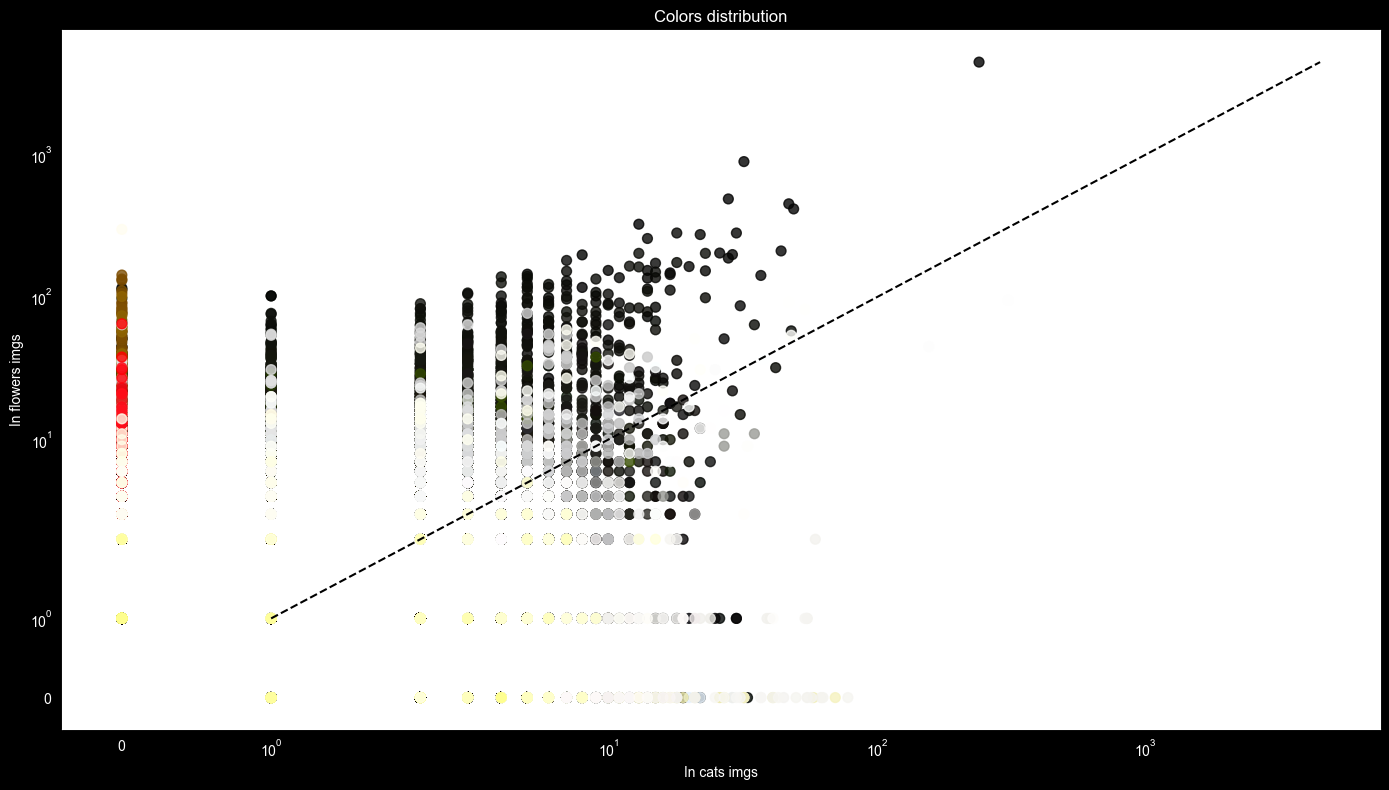

In [238]:
# b

colors_rgb = df_colors[['R', 'G', 'B']].values / 255.0

fig, ax = plt.subplots(figsize=(14, 8))
ax.set_facecolor('white')

ax.scatter(df_colors['count_in_cat'], df_colors['count_in_flower'], c=colors_rgb, alpha=0.8, s=50)

max_val = max(df_colors['count_in_flower'].max(), df_colors['count_in_cat'].max())
ax.plot([1, max_val], [1, max_val], color='black', linestyle='dashed')

# Ponieważ jeden punkt zawyża, dla lepszej widoczności skalujemy log (symlog, aby również widać było dla 0).
ax.set_xscale('symlog')
ax.set_yscale('symlog')

ax.set_title('Colors distribution')
ax.set_xlabel('In cats imgs')
ax.set_ylabel('In flowers imgs')

plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Komentarz:
Użyto skali logarytmicznej, aby wykres był bardziej czytelny, dzięki niej można zauważyć, że nieliczne barwy (prawy górny róg pomiędzy 10$^2$ a 10$^3$) pojawiają się tysiące razy dla obu kategorii, gdy ogromna liczba kolorów pojawia się bardzo rzadko (duże skupisko kolorów w przedziale [1, 10]). Zastosowano symlog zamiast log, aby pokazać też wystąpienia barw charakterystycznych tylko dla zdjęć kotów oraz kwiatów.

* **Barwy charakterystyczne**:
    * **dla kotów**: jasne, beżowe, żółtawe odcienie,
    * **dla kwiatów**: po lewej stronie wykresu widoczne są wyraźne skupiska barw nasyconych, takich jak np. czerwień oraz odcienie brązu. Ich położenie wskazuje, że barwy te występują tylko i wyłącznie na zdjęciach kwiatów (np. płatki).
    * **wspólne (przekątna y=x)**: głównie są to kolory neutralne, wspólne dla większości zdjęć takie jak odcienie szarości i bieli (np. kolory tła dla obu kategorii).

**Wniosek**:
Wyraźna separacja kolorów charakterystycznych dla danej kategorii (odpowiednie kolory dla x = 0 (kwiaty),  = 0 (koty)) daje duży potencjał w przyszłej separacji zdjęć na koty oraz kwiaty podczas algorytmu klasyfikacji.



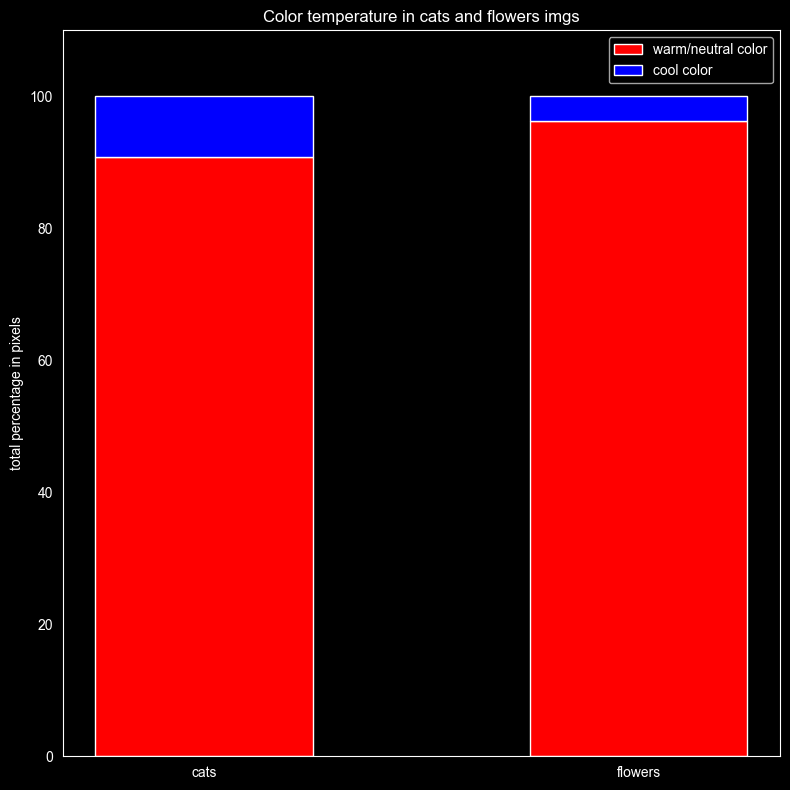

In [239]:
# c
cat_data = df_colors.groupby('is_cool_color')['count_in_cat'].sum()
flower_data = df_colors.groupby('is_cool_color')['count_in_flower'].sum()

# Przeskalowanie na procent, aby było lepiej porównywalne.
cats_total = cat_data.sum()
flower_total = flower_data.sum()

cats_perc = cat_data / cats_total * 100
flowers_perc = flower_data / flower_total * 100

plt.figure(figsize=(8, 8))
labels = ['cats', 'flowers']
warm_vals = [cats_perc[0], flowers_perc[0]]
cool_vals = [cats_perc[1], flowers_perc[1]]

plt.bar(labels, warm_vals, label='warm/neutral color', color='red', width=0.5, align='center')
plt.bar(labels, cool_vals, bottom=warm_vals ,label='cool color', color='blue', width=0.5, align='center')

plt.title('Color temperature in cats and flowers imgs')

plt.ylabel('total percentage in pixels')
plt.ylim(0, 110)
plt.grid(False)
plt.tight_layout()
plt.legend()
plt.show()


### Komentarz:
Zastosowano przeskalowanie do skali procentowej, aby lepiej ukazać udział barw ciepłych/neutralnych i zimnych na zdjęciach.
* **Dominacja barw ciepłych i naturalnych**: Duży wpływ na taki wynik może mieć największy wynik wykrycia kolorów takich jak odcienie bieli i czerni, które są uznawane za neutralne.
* **Różnice między kategoriami**: widać, że mimo wysokiego poziomu ciepłych i neutralnych kolorów w obu kategoriach, w przypadku kwiatów jest on większy o kilkanaście procent niż u kotów. Wpływ na to mogą mieć ciepłe odcienie płatków kwiatów, które zostały wykryte jako występujące tylko na zdjęciach kwiatów na poprzednim wykresie.


- - -

## 3: Klastrowanie - redukcja palety barw

### 3a

**Wybór zmiennych:** do klasteryzacji wybrano surowe wartości **RGB** bez dodatkowego skalowania. \
**Uzasadnienie:** wszystkie składowe **RGB** są w tym samym zakresie wartości [0, 255]. Dzięki temu każda ze składowych ma identyczny wpływ na obliczanie odległości między pikselami w przestrzeni barw. Zapobiega, to sytuacji, w której jedna ze składowych zaburzałaby wynik tylko ze względu na swój zakres wartości.


### 3b
Przeprowadzono klastrowanie dla każdego zdjęcia rozkodowanego na piksele przy użyciu 2 algorytmów: *k-średnich* oraz *k-median* (Kmedoids) dla k $\in$ [5,20].\
Wykonano dla każdego zdjęcia i algorytmu 5 razy obliczając z nich *średnią Silhoutte* oraz *wartość Caliński-Harabasz Index (CHI)*. \
(Wyniki zapisano do pliku "clustering_res.csv", aby zapobiec sytuacji, w której w przypadku restartu utracono by uzyskane wyniki, ponieważ poniższy kod wykonuje się bardzo długo.)


In [229]:
# 3a
from tqdm import tqdm

seeds = [1104, 12041, 130412, 140413, 150414]
k_vals = range(5, 21)

imgs = df_pixels['img_name'].unique()

clustering_res = []

for img in tqdm(imgs, desc='Przetwarzanie zdj'):
    img_data = df_pixels[df_pixels['img_name'] == img][['R', 'G', 'B']].values

    for k in k_vals:
        for alg in ['KMeans', 'Kmedoids']:
            sil_res = []
            chi_res = []
            for seed in seeds:
                if alg == 'KMeans':
                    model = KMeans(n_clusters=k, random_state=seed, n_init=1)
                else:
                    model = KMedoids(n_clusters=k, random_state=seed, init='k-medoids++', method='alternate')

                labels = model.fit_predict(img_data)

                sil = silhouette_score(img_data, labels, random_state=seed)
                chi = calinski_harabasz_score(img_data, labels)
                sil_res.append(sil)
                chi_res.append(chi)

            clustering_res.append({
                    'img': img,
                    'k': k,
                    'alg': alg,
                    'avg_sil': np.mean(sil_res),
                    'avg_chi': np.mean(chi_res),
            })

df_res = pd.DataFrame(clustering_res)

df_res.to_csv('clustering_res.csv', index=False)

In [240]:
df_res = pd.read_csv('clustering_res.csv')
df_res.head()

,img,k,alg,avg_sil,avg_chi
0,kwiatek-76.png,5,KMeans,0.491806,14448.883217
1,kwiatek-76.png,5,Kmedoids,0.460121,14096.727146
2,kwiatek-76.png,6,KMeans,0.453165,13939.433871
3,kwiatek-76.png,6,Kmedoids,0.441307,14064.754042
4,kwiatek-76.png,7,KMeans,0.425934,13335.726177


Teraz nasze wyniki znajdują się w *df_res* i zawierają następujące informacje:
* Nazwę pliku,
* Wartość k,
* Nazwę algorytmu,
* Wartośc avg_sil,
* Wartość avg_chi.

### 3c
Dla algorytmu *k-średnich* oraz *k-median* (Kmedoids) przygotowano po 2 wykresy skrzypcowe, dla każdej wartości k $\in$ [5,20] dla uzyskanych średnich *Silhouette* w 5 iteracjach na zdjęcie oraz dla średnich *CHI*, aby wyznaczyć optymalną wartość k.

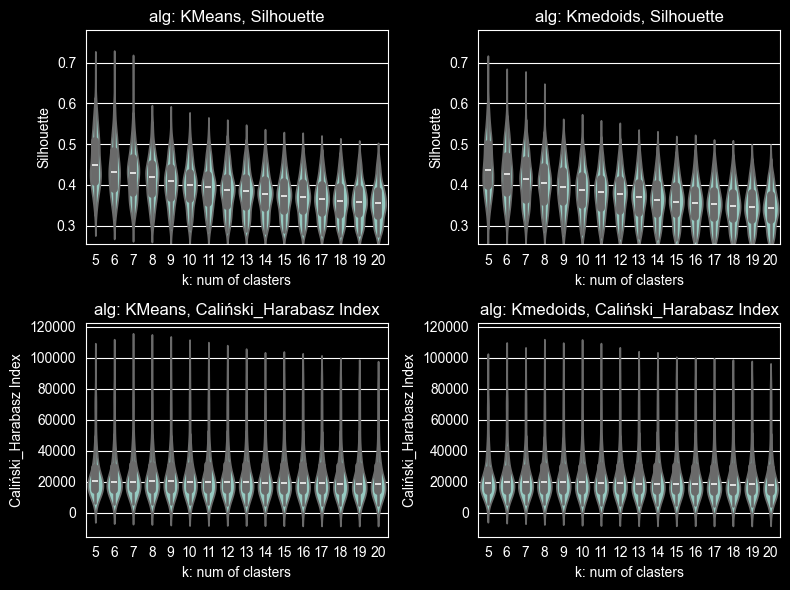

In [241]:
# 3c

fig, axs = plt.subplots(2, 2, figsize=(8, 6))

algs = ['KMeans', 'Kmedoids']
metrics = [('avg_sil', 'Silhouette'), ('avg_chi', 'Caliński_Harabasz Index')]

sil_min = df_res['avg_sil'].min()
sil_max = df_res['avg_sil'].max()
chi_min = df_res['avg_chi'].min()
chi_max = df_res['avg_chi'].max()

for i, alg in enumerate(algs):
    data = df_res[df_res['alg'] == alg]
    for j, (metric, label) in enumerate(metrics):
        sns.violinplot(ax=axs[j, i], x='k', y=metric, data=data)
        axs[j, i].set_title(f'alg: {alg}, {label}')
        axs[j, i].set_xlabel('k: num of clasters')
        axs[j, i].set_ylabel(label)
        if metric == 'avg_sil':
            axs[j, i].set_ylim([sil_min, sil_max + 0.1])
        else:
            axs[j, i].set_ylim([chi_min - 20000, chi_max + 20000])

plt.tight_layout()
plt.show()


### Komentarz:
* **KMeans**:
    * **Wybór k = 7**
        * **Uzasadnienie**: Najwyższe wartości *Silhouette* są osiągane dla małych k (5, 6, 7), a wraz ze wzrostem k (od 8 do 20) mediana systematycznie spada. Spośród tych 3 wartości k, to k = 7 ma najmniejszy rozrzut wartości, jednocześnie nie tracąc tak bardzo na wartości mediany (w porównaniu do k = 5, 6) oraz największe skupisko gęstości wokół mediany. Mediana dla *CHI* pozostaje stabilna dla wszystkich wartości k.

* **Kmedoids**:
    * **Wybór k = 6**
        * **Uzasadnienie**: Najwyższe wartości *Silhouette* podobnie jak w przypadku algorytmu *KMeans* osiągane są dla małych k (5, 6, 7) jednak wartości te bardziej spadają wraz ze wzrostem k. Rozrzut wartości jest jednak inny, teraz dla k = 6 mamy najlepszy kompromis pomiędzy wysoką medianą, małym rozrzutem oraz większą gęstością skupienia wokół mediany. Mediana dla *CHI* również jak w *KMeans* pozostaje stabilna dla wszystkich k.


### 3d: Tworzymy 2 zbiory danych (dla algorytmu *k-średnich* oraz *k-median*) zawierające zapisane zdjęcia po redukcji barw w postaci kodu z wybranego standardu barw środka danego skupienia.

In [242]:
# 3d

def reduce_colors(img, k, alg):
    img_data = df_pixels[df_pixels['img_name'] == img].sort_values(by=['y', 'x'])
    img_data = img_data[['R', 'G', 'B']].values
    if alg == 'KMedoids':
        model = KMedoids(n_clusters=k, random_state=1104, init='k-medoids++')
    else:
        model = KMeans(n_clusters=k, random_state=1104)

    labels = model.fit_predict(img_data)
    centers = model.cluster_centers_.astype(int)

    reduced_pixels = centers[labels]

    reduced_img = reduced_pixels.reshape((100, 100, 3))
    return reduced_img

reduced_imgs_kmeans = {}
reduced_imgs_kmedoids = {}

for img_name in df_pixels['img_name'].unique():
    reduced_imgs_kmeans[img_name] = reduce_colors(img_name, 7, 'KMeans')
    reduced_imgs_kmedoids[img_name] = reduce_colors(img_name, 6, 'KMedoids')

### 3e: Porównanie 5 zdjęć przed i po redukcji dla obu algorytmów.

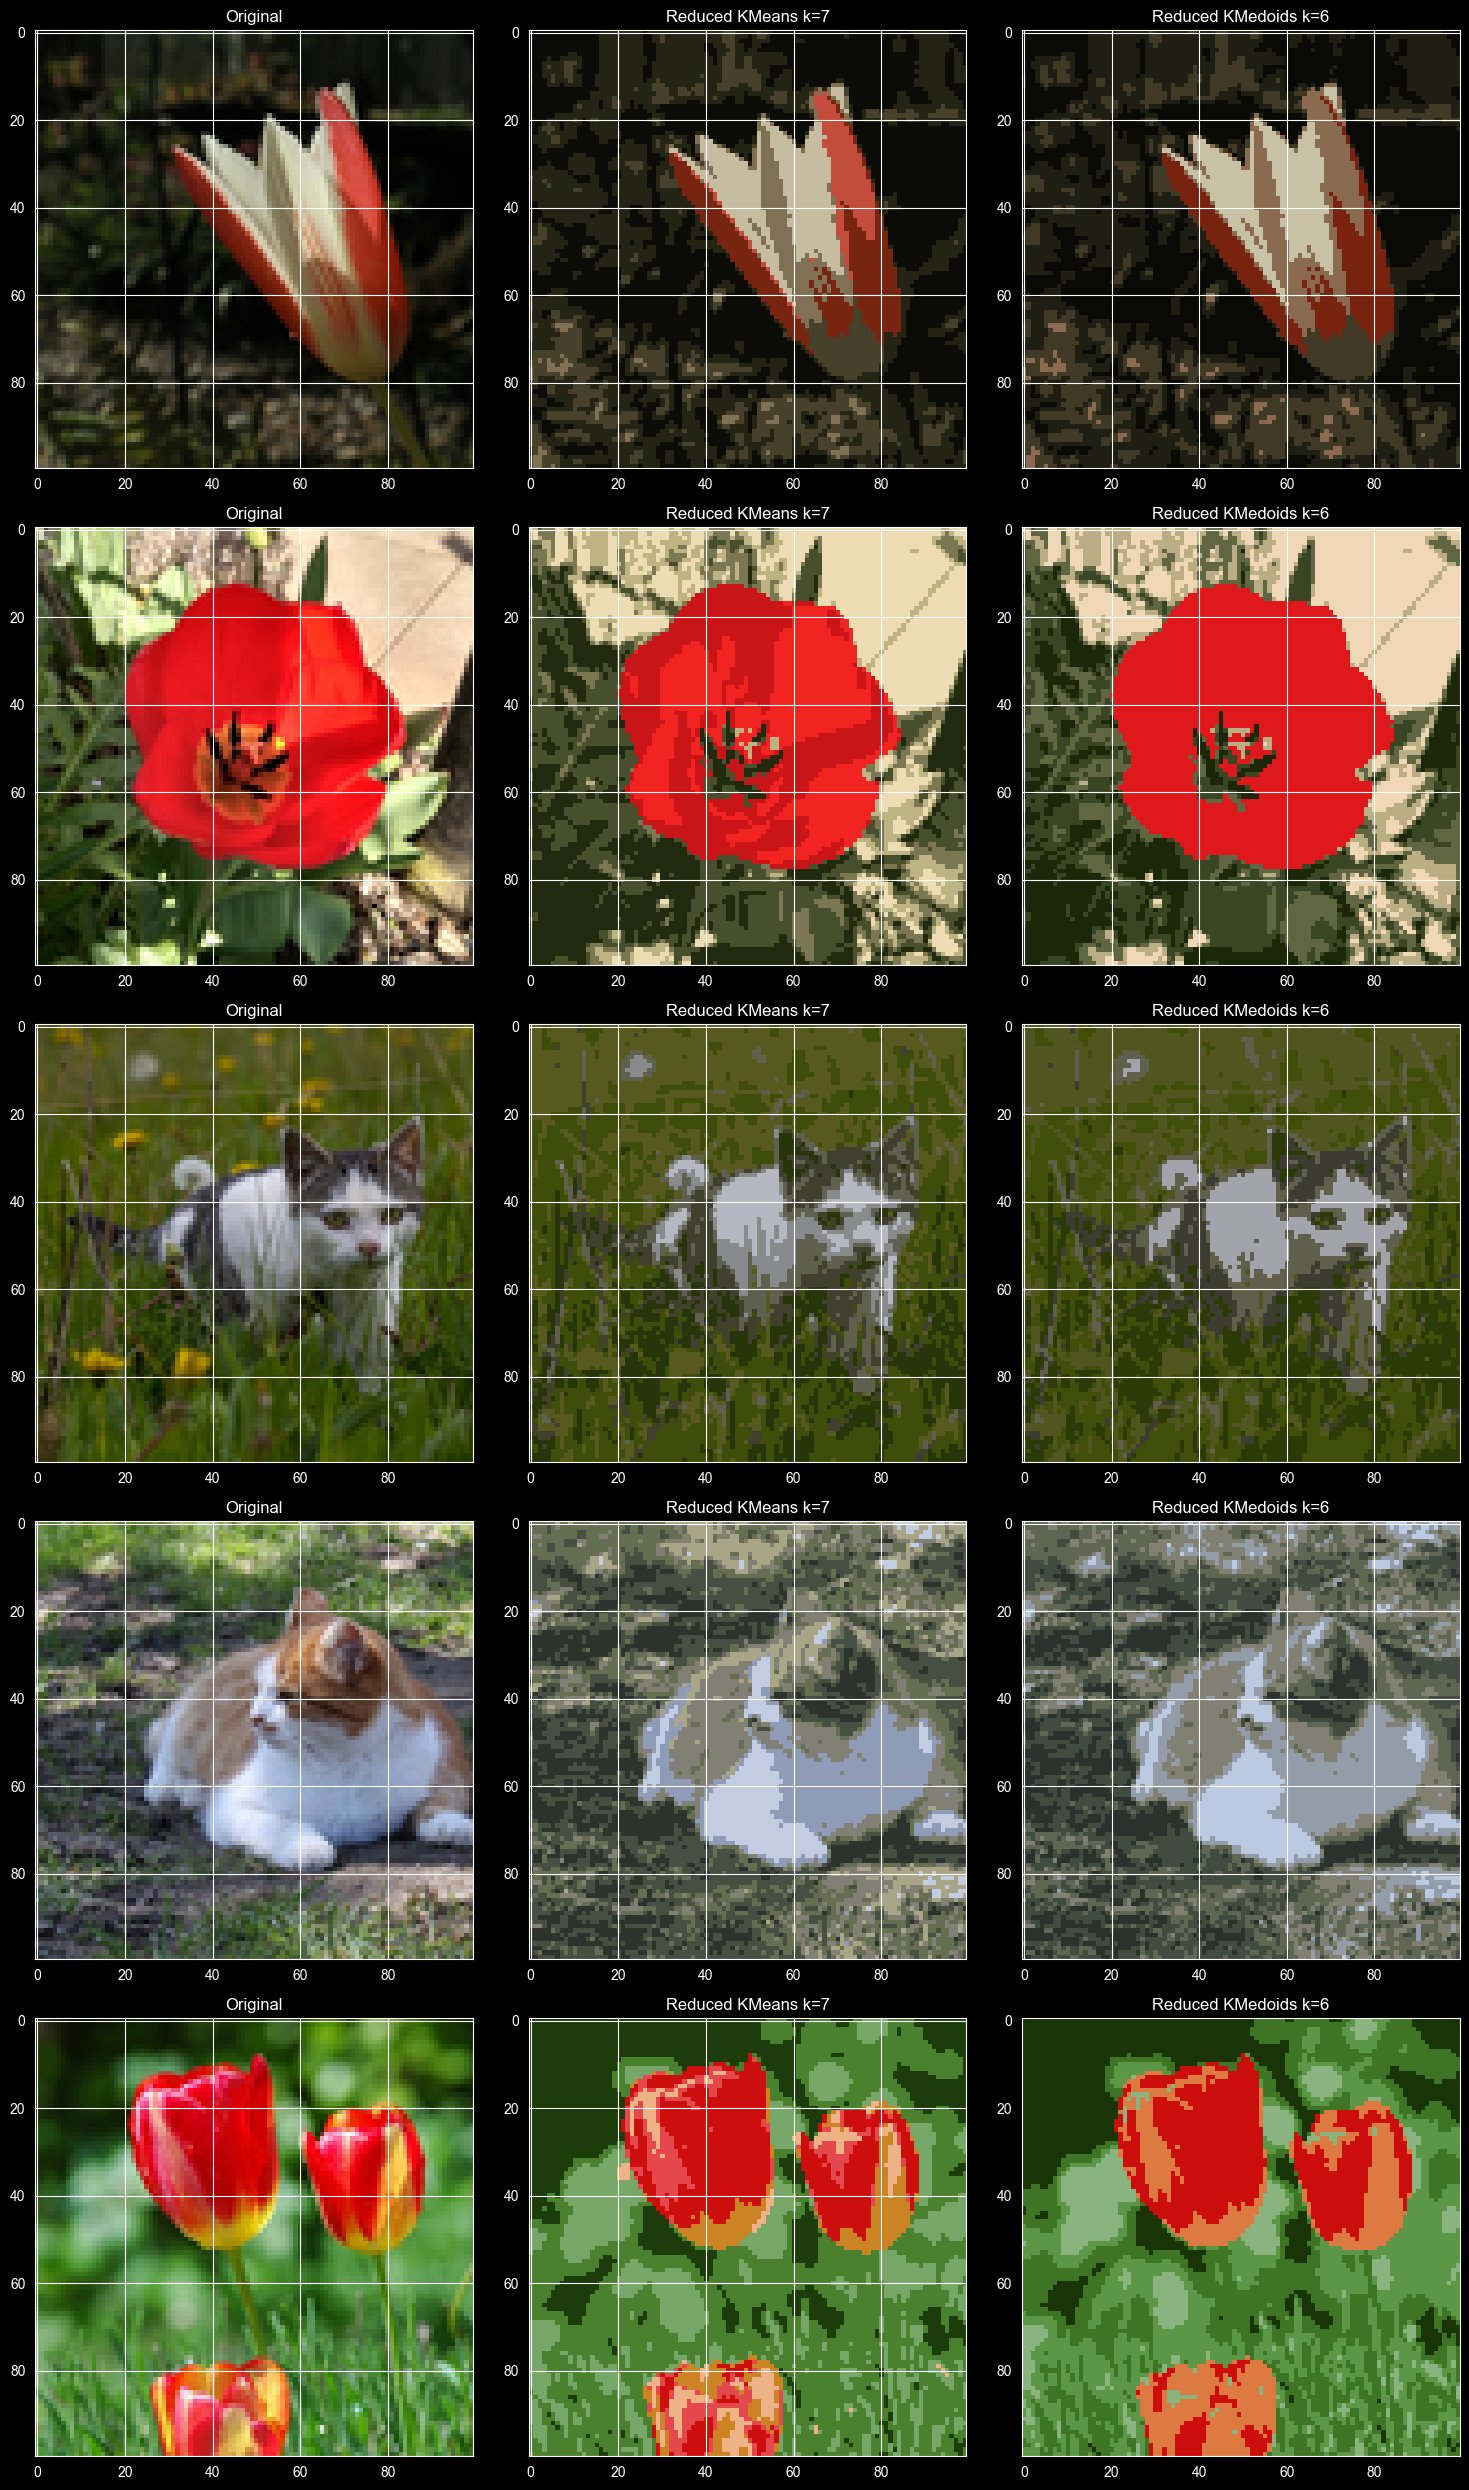

In [274]:
# 3e

all_imgs = df_pixels['img_name'].unique()

random_5_imgs = random.sample(list(all_imgs), 5)

fig, axs = plt.subplots(5, 3, figsize=(15, 25))
for i, img in enumerate(random_5_imgs):
    orig_img = Image.open(f'kot-kwiat/{random_5_imgs[i]}')

    red_kmeans = reduced_imgs_kmeans[img]
    red_kmedoids = reduced_imgs_kmedoids[img]

    axs[i, 0].imshow(orig_img)
    axs[i, 0].set_title('Original')

    axs[i, 1].imshow(red_kmeans)
    axs[i, 1].set_title('Reduced KMeans k=7')

    axs[i, 2].imshow(red_kmedoids)
    axs[i, 2].set_title('Reduced KMedoids k=6')

plt.grid(False)
plt.tight_layout()
plt.show()

**Wybór algorytmu**: KMeans, k = 7\
**Uzasadnienie** Zdjęcie jest lepiej odwzorowane, kolory są bardziej podobne do oryginału oraz ilość szczegółów jest większa. Dodatkowo na zdjęciach lepiej widać cieniowanie, refleksy światła niż na tych zredukowanych przy pomocy Kmedoids, które nie mają takiej głębi koloru.


- - -

## 4: Analiza zysku z kompresji

Badamy zależność między liczbą unikatowych kolorów na zdjęciu a oszczędnością miejsca po redukcji palety barw.
Dla każdego zdjęcia zapisujemy nowe w katalogu "reduced_imgs", po redukcji kolorów i obliczamy procentowy zysk z tej kompresji.

In [244]:
results = []
os.makedirs('reduced_imgs', exist_ok=True)
for img_name in df_pixels['img_name'].unique():
    reduced_img = reduced_imgs_kmeans[img_name]
    reduced_img_save = Image.fromarray(reduced_img.astype('uint8'))
    reduced_img_save.save(f'reduced_imgs/{img_name}')

    unique_colors = unique_colors_per_img[unique_colors_per_img['img_name'] == img_name]['unique_count'].values[0]
    size_orig = os.path.getsize(f'kot-kwiat/{img_name}')

    size_red = os.path.getsize(f'reduced_imgs/{img_name}')
    gain = (size_orig - size_red) / size_orig * 100

    results.append({
        'img': img_name,
        'unique_colors': unique_colors,
        'gain': gain
    })

In [245]:
df_results = pd.DataFrame(results)
df_results.sort_values(by=['gain'], ascending=False)

,img,unique_colors,gain
49,kwiatek-14.png,7704,93.224365
64,kotek-43.png,8218,91.384267
41,kotek-10.png,7918,91.318262
4,kotek-14.png,9492,90.955092
118,kotek-32.png,9534,90.857784
...,...,...,...
24,kwiatek-70.png,9209,71.808066
9,kotek-6.png,9608,71.597255
16,kotek-17.png,9873,69.960460
116,kotek-27.png,9846,69.080102


### Komentarz
Widać znaczny zysk z kompresji (od ~68% do aż ~93%). Jednocześnie można już zauważyć, że wcale największy zysk z kompresji nie oznacza, że zdjęcie miało dużo, bądź mało unikalnych barw (zdjęcie, które ma zysk rzędu ~90% posiada 9534 unikalne barwy, a zdjęcie z zyskiem jedynie ~71% ma ich 9608).

### Regresja
Badamy zależność pomiędzy zyskiem z kompresji zdjęcia a liczbą unikatowych barw na zdjęciu, wykorzystujemy do tego:
* model liniowy,
* model logarytmiczny (regresja liniowa z wykorzystaniem zlogarytmowanej wartości zmiennej objaśniającej X),
* model wielomianowy (stopnia 3).

In [246]:
X = df_results[['unique_colors']].values
y = df_results['gain'].values

model = LinearRegression()
model.fit(X, y)
print("Linear: ", model.score(X, y))

X_log = np.log(X)
model_log = LinearRegression()
model_log.fit(X_log, y)
print("Log: ", model_log.score(X_log, y))

poly = PolynomialFeatures(degree=3)
X_poly = poly.fit_transform(X)
model_poly = LinearRegression()
model_poly.fit(X_poly, y)
print("Poly: ", model_poly.score(X_poly, y))

Linear:  0.0561094208786973
Log:  0.04855971284630034
Poly:  0.1179201556323567


### Komentarz
Najwyższą wartość $R^2$ = ~0.12 uzyskano dla modelu wielomianowego, jednak jest ona również relatywnie niska, co sugeruje, że zależność między zyskiem z kompresji a liczbą unikatowych barw jest mała, a wpływ na zysk z kompresji mają również inne cechy (sugeruje to głównie bardzo mały, dwukrotnie niższy wynik dla regresji liniowej).

- - -

## 5: Wpływ redukcji palety barw na klasyfikacje binarną z użyciem metody kNN.

### 5a: Przygotowanie danych
Dla każdego zdjęcia przygotowujemy:
* zmiennę binarną y: czy zdjęcie przedstawia kota,
* wektor opisujący barwy na kolejnych pikselach w wersji w oryginalnym zdjęciu oraz "skompresowanym" zdjęciu o wymiarach 133 w x 10 000 k. Aby uzyskać 10 000 kolumn, kodujemy jednoznacznie wartości RGB w jedną, wykonując następującą translację: $10^6$*R + $10^3$*B + G.


In [247]:
# 5a

def prepare_data(is_reduced):
    y = []
    X_orig = []
    X_red = []

    for img in df_pixels['img_name'].unique():
        y.append(1 if 'kotek' in img else 0)

        if is_reduced:
            img_pxls = reduced_imgs_kmeans[img]

            r = img_pxls[:, :, 0].flatten()
            g = img_pxls[:, :, 1].flatten()
            b = img_pxls[:, :, 2].flatten()

            X = (10**6)*r + (10**3)*g + b
            X_red.append(X)

        else:
            img_df = df_pixels[df_pixels['img_name'] == img].sort_values(by=['y', 'x'])

            r = img_df['R'].values
            g = img_df['G'].values
            b = img_df['B'].values

            X = (10**6)*r + (10**3)*g + b
            X_orig.append(X)

    if is_reduced:
        return np.array(X_red), np.array(y)
    else:
        return np.array(X_orig), np.array(y)


X_orig, y = prepare_data(is_reduced = False)
X_red, _ = prepare_data(is_reduced = True)

print("Original: ", X_orig.shape)
print("Reduced: ", X_red.shape)
print("y", y.shape)

Original:  (132, 10000)
Reduced:  (132, 10000)
y (132,)


### 5b: Dzielimy naszą uzyskaną bazę danych na część treningową (90%) oraz testową (10%).

In [248]:
# 5b
X_train_orig, X_test_orig, y_train, y_test = train_test_split(X_orig, y, test_size=0.1, random_state=42, stratify=y)
X_train_red, X_test_red, _, _ = train_test_split(X_red, y, test_size=0.1, random_state=42, stratify=y)

### 5c: Przeprowadzamy klasyfikację algorytmem *kNN* z wykorzystaniem 5-krotnej walidacji krzyżowej do wyboru optymalnego *hiperparametru* dla zbioru oryginalnego oraz zredukowanego.

In [249]:
# 5c
knn_orig = GridSearchCV(KNeighborsClassifier(), param_grid={'n_neighbors': range(1, 15)}, cv=5, scoring='f1')
knn_orig.fit(X_train_orig, y_train)

knn_red = GridSearchCV(KNeighborsClassifier(), param_grid={'n_neighbors': range(1, 15)}, cv=5, scoring='f1')
knn_red.fit(X_train_red, y_train)

print(f'Best hyperparam for orig: {knn_orig.best_params_}')
print(f'Best hyperparam for red: {knn_red.best_params_}')

Best hyperparam for orig: {'n_neighbors': 5}
Best hyperparam for red: {'n_neighbors': 11}


### 5d: Porównanie miary *F1* dla danych oryginalnych i skompresowanych na zbioze treningowym, walidacyjnym oraz testowym.

In [250]:
# 5d

print('-------------------original--------vs-------reduced--------------------')
print(f'training:    {  f1_score(y_train, knn_orig.predict(X_train_orig))}    ||       {f1_score(y_train, knn_red.predict(X_train_red))}')
print(f'validation:  {knn_orig.best_score_}    ||       {knn_red.best_score_}')
print(f'test:        {f1_score(y_test, knn_orig.predict(X_test_orig))}                 ||       {f1_score(y_test, knn_red.predict(X_test_red))}')
print('-----------------------------------------------------------------------')


-------------------original--------vs-------reduced--------------------
training:    0.7563025210084033    ||       0.7413793103448276
validation:  0.6930432530432531    ||       0.6967132867132867
test:        0.625                 ||       0.625
-----------------------------------------------------------------------


### Wyniki i wnioski



Zastosowanie kompresji **nie** pogorszyło znacząco jakości klasyfikacji. Wyniki dla zbioru treningowego, walidacyjnego oraz testowego są bardzo zbliżone dla danych oryginalnych i po redukcji (różnica na korzyść oryginalnego dla zbioru treningowego (\~0.01), na korzyść zredukowanego dla walidacyjnego (\~0.003), a dla testowego wyniki takie same). Oznacza, to, że faktycznie przy takiej liczbie unikatowych barw, zmniejszenie palety barw zadziałało poprawnie i dobrze, usuwając niepotrzebnie duże dane i upraszczając dane wejściowe.